# 06 · The simulation wall: what it costs to simulate qubits classically

**QGAI open notebooks · Track: Quantum + HPC**

Every quantum result in these notebooks comes from a **classical simulator**. A statevector simulator stores $2^n$ complex
amplitudes for $n$ qubits, so memory and time double with every qubit. This notebook measures that wall on the machine it runs on,
compares two simulators, and works out what it means for planning hybrid quantum-HPC work.

Measured: wall-clock time to run a fixed random circuit (10 layers of rotations and entangling CNOTs) for $n = 4 \dots 22$ qubits on

- `default.qubit`: PennyLane's reference simulator (Python/NumPy)
- `lightning.qubit`: PennyLane's optimised C++ simulator

Timings depend on hardware, so expect different absolute numbers on your machine; the **doubling per qubit** is the point.

In [1]:
import os, time, platform
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

SEED = 9
rng = np.random.default_rng(SEED)
print(f"machine: {platform.processor() or platform.machine()}, {os.cpu_count()} CPU cores, Python {platform.python_version()}, PennyLane {qml.__version__}")

machine: x86_64, 4 CPU cores, Python 3.13.18, PennyLane 0.45.1


## Memory: the wall on paper
One complex amplitude in double precision takes 16 bytes.

In [2]:
def human(nbytes):
    for unit in ["B", "KiB", "MiB", "GiB", "TiB", "PiB", "EiB"]:
        if nbytes < 1024: return f"{nbytes:,.0f} {unit}"
        nbytes /= 1024
    return f"{nbytes:,.0f} ZiB"

for n in [10, 20, 30, 35, 40, 45, 50, 60]:
    print(f"{n:>3} qubits -> {2 ** n:>26,d} amplitudes -> {human(16 * 2 ** n):>12s}")

try:
    ram = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
    max_n = int(np.floor(np.log2(ram / 2 / 16)))   # leave half the RAM for the simulator's working copies and the OS
    print(f"\nThis machine: {human(ram)} of RAM -> largest practical statevector is about {max_n} qubits")
except (ValueError, OSError, AttributeError):
    print("\n(could not read this machine's RAM size)")

 10 qubits ->                      1,024 amplitudes ->       16 KiB
 20 qubits ->                  1,048,576 amplitudes ->       16 MiB
 30 qubits ->              1,073,741,824 amplitudes ->       16 GiB
 35 qubits ->             34,359,738,368 amplitudes ->      512 GiB
 40 qubits ->          1,099,511,627,776 amplitudes ->       16 TiB
 45 qubits ->         35,184,372,088,832 amplitudes ->      512 TiB
 50 qubits ->      1,125,899,906,842,624 amplitudes ->       16 PiB
 60 qubits ->  1,152,921,504,606,846,976 amplitudes ->       16 EiB

This machine: 16 GiB of RAM -> largest practical statevector is about 28 qubits


## Time: measured
The same random circuit for each size: 10 layers, each with an $R_Y$ and $R_Z$ rotation on every qubit and a chain of CNOTs. We time a single
expectation value $\langle Z_0 \rangle$, best of 3 runs.

In [3]:
LAYERS = 10

def make_circuit(dev_name, n):
    dev = qml.device(dev_name, wires=n)
    @qml.qnode(dev)
    def circuit(a, b):
        for l in range(LAYERS):
            for w in range(n):
                qml.RY(a[l, w], wires=w); qml.RZ(b[l, w], wires=w)
            for w in range(n - 1):
                qml.CNOT(wires=[w, w + 1])
        return qml.expval(qml.PauliZ(0))
    return circuit

def time_it(dev_name, n, repeats=3):
    c = make_circuit(dev_name, n)
    a, b = rng.uniform(0, np.pi, (LAYERS, n)), rng.uniform(0, np.pi, (LAYERS, n))
    c(a, b)  # warm-up (compilation, caches)
    best = np.inf
    for _ in range(repeats):
        t = time.perf_counter(); c(a, b); best = min(best, time.perf_counter() - t)
    return best

sizes = {"default.qubit": list(range(4, 21, 2)), "lightning.qubit": list(range(4, 23, 2))}
timings = {}
for dev_name, ns in sizes.items():
    timings[dev_name] = [time_it(dev_name, n) for n in ns]
    for n, t in zip(ns, timings[dev_name]):
        print(f"{dev_name:16s} {n:>3} qubits: {t * 1000:>10.1f} ms")

default.qubit      4 qubits:        4.6 ms
default.qubit      6 qubits:        7.0 ms
default.qubit      8 qubits:        9.7 ms
default.qubit     10 qubits:       12.7 ms
default.qubit     12 qubits:       18.0 ms
default.qubit     14 qubits:       30.6 ms
default.qubit     16 qubits:      151.0 ms
default.qubit     18 qubits:      619.7 ms
default.qubit     20 qubits:     1777.2 ms


lightning.qubit    4 qubits:        2.5 ms
lightning.qubit    6 qubits:        3.5 ms
lightning.qubit    8 qubits:        4.5 ms
lightning.qubit   10 qubits:        5.7 ms
lightning.qubit   12 qubits:        7.1 ms
lightning.qubit   14 qubits:        9.6 ms
lightning.qubit   16 qubits:       17.1 ms
lightning.qubit   18 qubits:       80.6 ms
lightning.qubit   20 qubits:      324.5 ms
lightning.qubit   22 qubits:     1348.9 ms


## Growth rate and extrapolation
Fit $\log_2 t$ against $n$ on the larger sizes (where fixed overheads no longer dominate). A slope of 1 means time doubles per qubit.

default.qubit    time grows ×1.97 per added qubit (n ≥ 14)
lightning.qubit  time grows ×1.90 per added qubit (n ≥ 14)


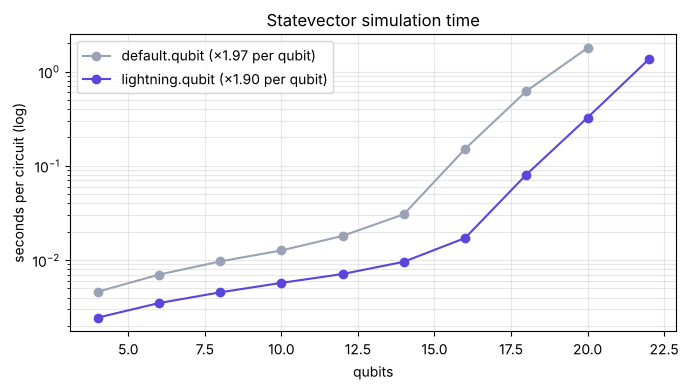


Extrapolated time per circuit on this machine (lightning.qubit), if memory allowed:
 26 qubits:           15.2 s  (~0.00 h)  needs 1 GiB of memory
 30 qubits:          197.9 s  (~0.05 h)  needs 16 GiB of memory
 34 qubits:        2,576.8 s  (~0.72 h)  needs 256 GiB of memory
 40 qubits:      121,044.1 s  (~33.62 h)  needs 16 TiB of memory


In [4]:
colors = {"default.qubit": "#9aa3b5", "lightning.qubit": "#5a45dd"}
plt.figure(figsize=(7, 4))
fits = {}
for dev_name, ns in sizes.items():
    ns_a, ts = np.array(ns), np.array(timings[dev_name])
    big = ns_a >= 14
    slope, intercept = np.polyfit(ns_a[big], np.log2(ts[big]), 1)
    fits[dev_name] = (slope, intercept)
    plt.semilogy(ns, ts, "o-", color=colors[dev_name], label=f"{dev_name} (×{2 ** slope:.2f} per qubit)")
    print(f"{dev_name:16s} time grows ×{2 ** slope:.2f} per added qubit (n ≥ 14)")
plt.xlabel("qubits"); plt.ylabel("seconds per circuit (log)"); plt.title("Statevector simulation time")
plt.grid(alpha=0.3, which="both"); plt.legend(); plt.tight_layout(); plt.show()

slope, intercept = fits["lightning.qubit"]
print("\nExtrapolated time per circuit on this machine (lightning.qubit), if memory allowed:")
for n in [26, 30, 34, 40]:
    t = 2 ** (slope * n + intercept)
    print(f"{n:>3} qubits: {t:>14,.1f} s  (~{t / 3600:,.2f} h)  needs {human(16 * 2 ** n)} of memory")

## What this means for hybrid quantum-HPC work

- **Doubling is real.** Both simulators show time growing by roughly 2× per qubit once circuits are large enough (see the fitted factors above). The optimised simulator wins by a constant factor, not a different growth rate.
- **Memory is the hard stop.** The memory cell above shows the largest statevector this machine can hold (a few dozen qubits at most on any laptop or server); a 40-qubit statevector needs 16 TiB, which only large supercomputers have; each further qubit doubles that again. Published full statevector simulations top out in the mid-to-high 40s of qubits on the largest systems.
- **Entanglement, not qubit count, sets the true cost.** Circuits with little entanglement can be simulated far beyond this wall with tensor-network methods. That makes them the honest classical baseline any quantum advantage claim must beat.
- **Planning rule for QGAI experiments:** develop and benchmark below ~30 qubits on GPU or CPU simulators; move to real QPUs only for questions the simulator cannot answer (realistic noise, or sizes past the wall); and always report the classical-simulation cost alongside the quantum result.

**Try next:** add GPU simulation (`lightning.gpu` or NVIDIA CUDA-Q) and compare; vary depth instead of width; try a low-entanglement circuit with a tensor-network simulator.